In [30]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [31]:
items = pd.read_csv('items.csv')
resturants = pd.read_csv('resturants.csv')
sales = pd.read_csv('sales.csv')

### Preliminary Analysis: Examining Dataset Structure and Missing Values

Let's examine the `items` dataframe first:

In [32]:
print('--- items.info() ---')
items.info()
print('\n--- items.head() ---')
display(items.head())
print('\n--- items.describe() ---')
display(items.describe())
print('\n--- Missing values in items ---')
display(items.isnull().sum())

--- items.info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        100 non-null    int64  
 1   store_id  100 non-null    int64  
 2   name      100 non-null    object 
 3   kcal      100 non-null    int64  
 4   cost      100 non-null    float64
dtypes: float64(1), int64(3), object(1)
memory usage: 4.0+ KB

--- items.head() ---


,id,store_id,name,kcal,cost
0,1,4,Chocolate Cake,554,6.71
1,2,4,Breaded Fish with Vegetables Meal,772,15.09
2,3,1,Sweet Fruity Cake,931,29.22
3,4,1,Amazing Steak Dinner with Rolls,763,26.42
4,5,5,Milk Cake,583,6.07



--- items.describe() ---


,id,store_id,kcal,cost
count,100.000000,100.000000,100.000000,100.000000
mean,50.500000,3.520000,536.730000,11.763700
std,29.011492,1.708446,202.212852,8.991254
min,1.000000,1.000000,78.000000,1.390000
25%,25.750000,2.000000,406.250000,5.280000
50%,50.500000,4.000000,572.500000,7.625000
75%,75.250000,5.000000,638.250000,18.790000
max,100.000000,6.000000,1023.000000,53.980000



--- Missing values in items ---


,0
id,0
store_id,0
name,0
kcal,0
cost,0


Now, let's examine the `resturants` dataframe:

In [33]:
print('--- resturants.info() ---')
resturants.info()
print('\n--- resturants.head() ---')
display(resturants.head())
print('\n--- resturants.describe() ---')
display(resturants.describe())
print('\n--- Missing values in resturants ---')
display(resturants.isnull().sum())

--- resturants.info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      6 non-null      int64 
 1   name    6 non-null      object
dtypes: int64(1), object(1)
memory usage: 228.0+ bytes

--- resturants.head() ---


,id,name
0,1,Bob's Diner
1,2,Beachfront Bar
2,3,Sweet Shack
3,4,Fou Cher
4,5,Corner Cafe



--- resturants.describe() ---


,id
count,6.000000
mean,3.500000
std,1.870829
min,1.000000
25%,2.250000
50%,3.500000
75%,4.750000
max,6.000000



--- Missing values in resturants ---


,0
id,0
name,0


Finally, let's examine the `sales` dataframe:

In [34]:
print('--- sales.info() ---')
sales.info()
print('\n--- sales.head() ---')
display(sales.head())
print('\n--- sales.describe() ---')
display(sales.describe())
print('\n--- Missing values in sales ---')
display(sales.isnull().sum())

--- sales.info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   date        109600 non-null  object 
 1   item_id     109600 non-null  int64  
 2   price       109600 non-null  float64
 3   item_count  109600 non-null  float64
dtypes: float64(2), int64(1), object(1)
memory usage: 3.3+ MB

--- sales.head() ---


,date,item_id,price,item_count
0,2019-01-01,3,29.22,2.0
1,2019-01-01,4,26.42,22.0
2,2019-01-01,12,4.87,7.0
3,2019-01-01,13,4.18,12.0
4,2019-01-01,16,3.21,136.0



--- sales.describe() ---


,item_id,price,item_count
count,109600.000000,109600.000000,109600.000000
mean,50.500000,11.763700,6.339297
std,28.866202,8.946225,30.003728
min,1.000000,1.390000,0.000000
25%,25.750000,5.280000,0.000000
50%,50.500000,7.625000,0.000000
75%,75.250000,18.790000,0.000000
max,100.000000,53.980000,570.000000



--- Missing values in sales ---


,0
date,0
item_id,0
price,0
item_count,0


### Merging the Datasets

In [35]:
# Rename 'id' columns in items and resturants to avoid conflicts during merge
items_renamed = items.rename(columns={'id': 'item_id_item', 'name': 'item_name'})
resturants_renamed = resturants.rename(columns={'id': 'store_id_restaurant', 'name': 'store_name'})

# Merge sales with items_renamed on item_id
merged_df = sales.merge(items_renamed, left_on='item_id', right_on='item_id_item', how='left')

# Merge the result with resturants_renamed on store_id
merged_df = merged_df.merge(resturants_renamed, left_on='store_id', right_on='store_id_restaurant', how='left')

# Convert 'date' column to datetime objects
merged_df['date'] = pd.to_datetime(merged_df['date'])

# Select and reorder columns as requested
final_df = merged_df[['date', 'item_id', 'price', 'item_count', 'item_name', 'kcal', 'store_id', 'store_name']]

print('--- Merged DataFrame Info ---')
final_df.info()
print('\n--- Merged DataFrame Head ---')
display(final_df.head())
print('\n--- Missing values in final_df ---')
display(final_df.isnull().sum())

--- Merged DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109600 entries, 0 to 109599
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   date        109600 non-null  datetime64[ns]
 1   item_id     109600 non-null  int64         
 2   price       109600 non-null  float64       
 3   item_count  109600 non-null  float64       
 4   item_name   109600 non-null  object        
 5   kcal        109600 non-null  int64         
 6   store_id    109600 non-null  int64         
 7   store_name  109600 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(2)
memory usage: 6.7+ MB

--- Merged DataFrame Head ---


,date,item_id,price,item_count,item_name,kcal,store_id,store_name
0,2019-01-01,3,29.22,2.0,Sweet Fruity Cake,931,1,Bob's Diner
1,2019-01-01,4,26.42,22.0,Amazing Steak Dinner with Rolls,763,1,Bob's Diner
2,2019-01-01,12,4.87,7.0,Fantastic Sweet Cola,478,1,Bob's Diner
3,2019-01-01,13,4.18,12.0,Sweet Frozen Soft Drink,490,1,Bob's Diner
4,2019-01-01,16,3.21,136.0,Frozen Milky Smoothy,284,1,Bob's Diner



--- Missing values in final_df ---


,0
date,0
item_id,0
price,0
item_count,0
item_name,0
kcal,0
store_id,0
store_name,0


### Checking for Outliers

--- Descriptive Statistics of Numerical Columns ---


,date,item_id,price,item_count,kcal,store_id
count,109600,109600.000000,109600.000000,109600.000000,109600.000000,109600.00000
mean,2020-07-01 12:00:00,50.500000,11.763700,6.339297,536.730000,3.52000
min,2019-01-01 00:00:00,1.000000,1.390000,0.000000,78.000000,1.00000
25%,2019-10-01 18:00:00,25.750000,5.280000,0.000000,406.250000,2.00000
50%,2020-07-01 12:00:00,50.500000,7.625000,0.000000,572.500000,4.00000
75%,2021-04-01 06:00:00,75.250000,18.790000,0.000000,638.250000,5.00000
max,2021-12-31 00:00:00,100.000000,53.980000,570.000000,1023.000000,6.00000
std,NaN,28.866202,8.946225,30.003728,201.200165,1.69989


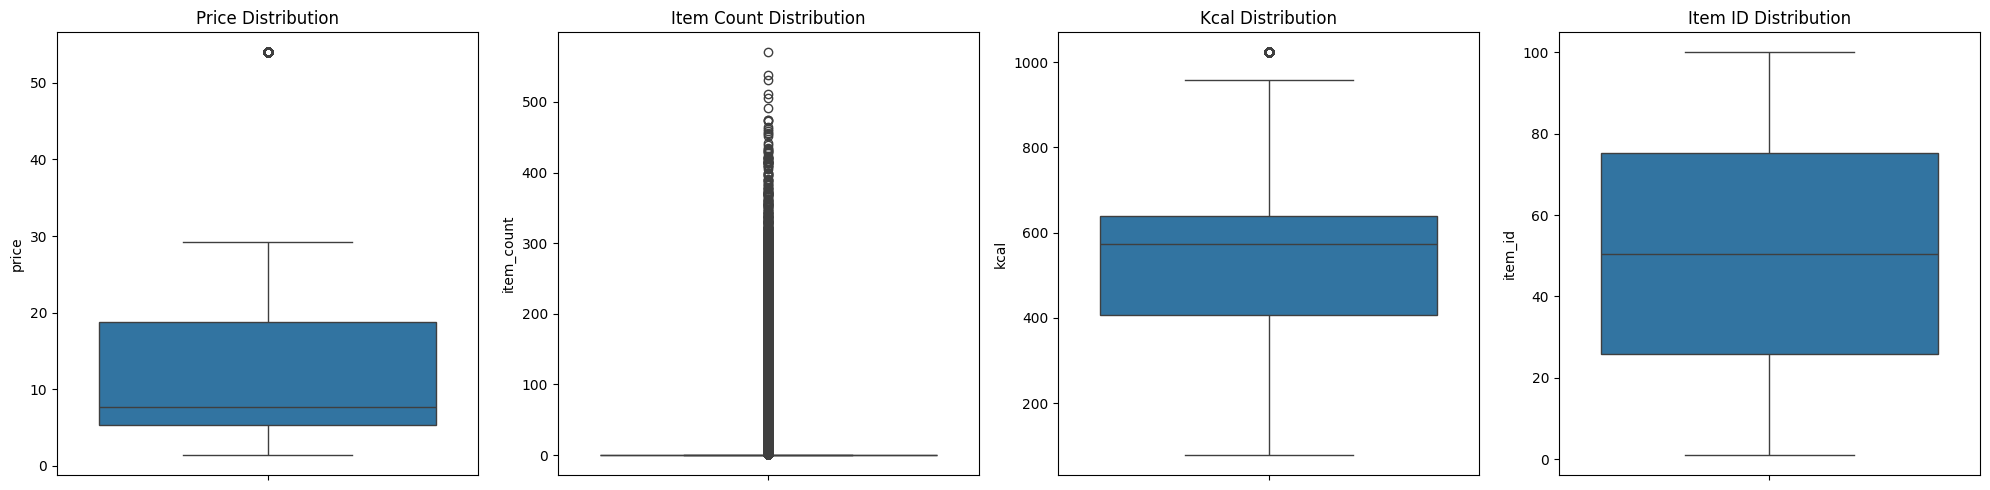

In [39]:
# Check for outliers in numerical columns using describe() and box plots
print('--- Descriptive Statistics of Numerical Columns ---')
display(final_df.describe())

# Create box plots for numerical columns to visualize outliers
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
sns.boxplot(y=final_df['price'], ax=axes[0])
axes[0].set_title('Price Distribution')
sns.boxplot(y=final_df['item_count'], ax=axes[1])
axes[1].set_title('Item Count Distribution')
sns.boxplot(y=final_df['kcal'], ax=axes[2])
axes[2].set_title('Kcal Distribution')
sns.boxplot(y=final_df['item_id'], ax=axes[3])
axes[3].set_title('Item ID Distribution')
plt.tight_layout()
plt.show()

### Exploratory Data Analysis: Sales Distribution by Quarter

Now, let's analyze the sales distribution across different quarters, averaged over the years, to identify any noticeable patterns.

--- Average Sales by Quarter ---


/tmp/ipykernel_512/917512532.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['total_sales'] = final_df['price'] * final_df['item_count']
/tmp/ipykernel_512/917512532.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_df['quarter'] = final_df['date'].dt.quarter


,quarter,total_sales
0,Q1,422841.430000
1,Q2,642879.206667
2,Q3,633997.050000
3,Q4,434861.796667


/tmp/ipykernel_512/917512532.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=average_sales_by_quarter, x='quarter', y='total_sales', palette='plasma')


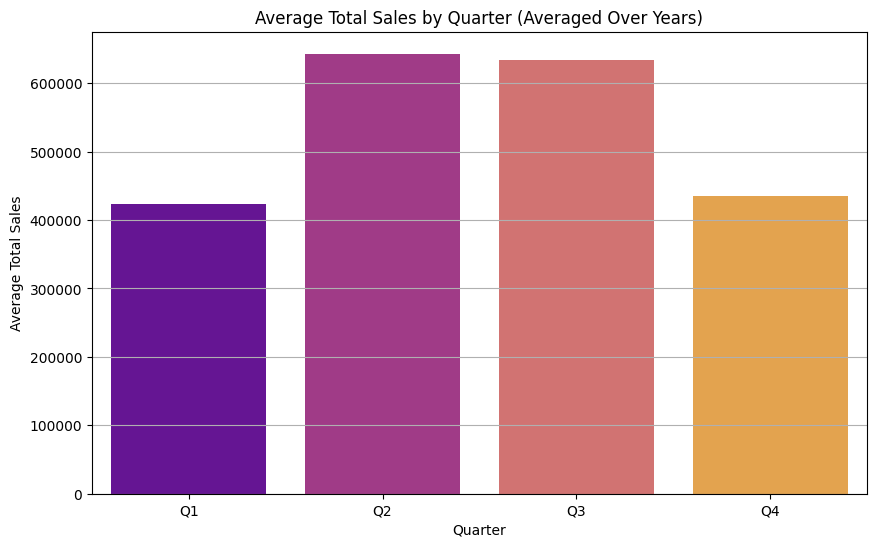

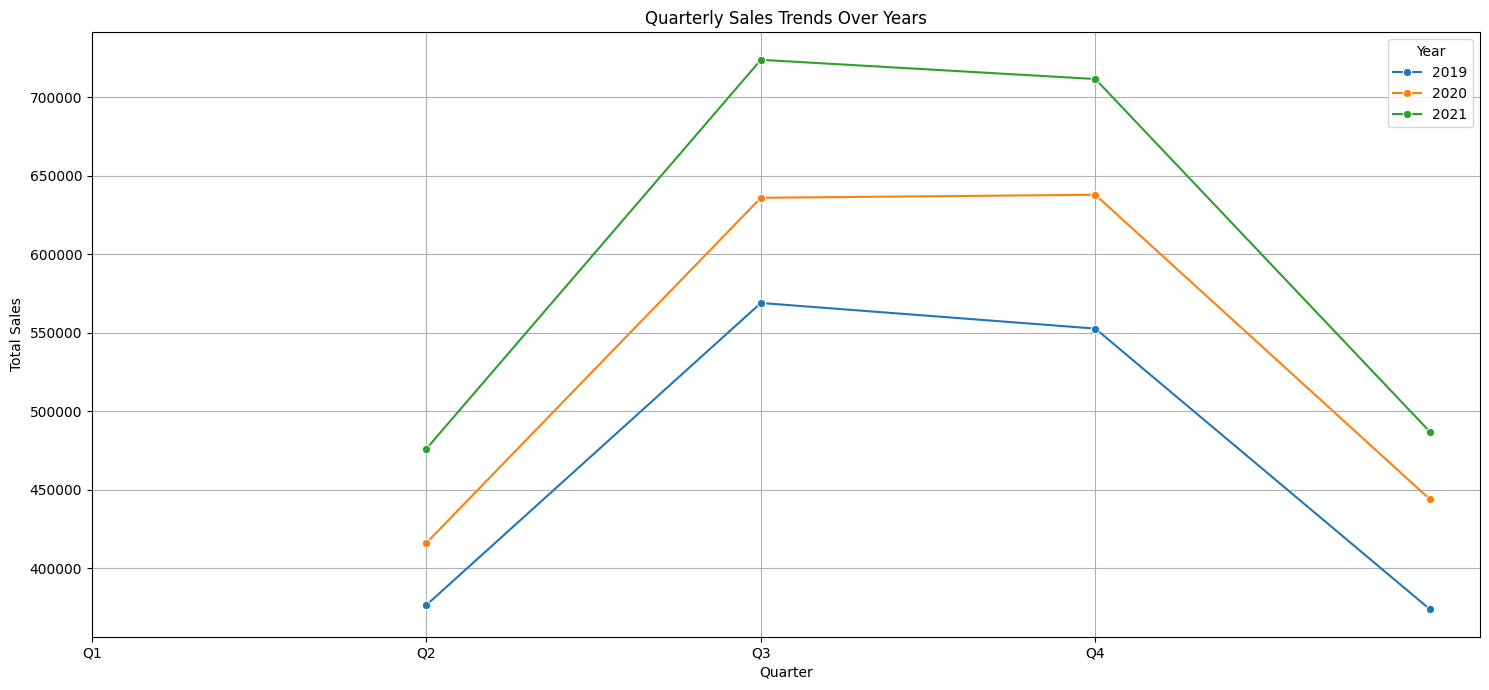

In [42]:
# Ensure 'total_sales' column exists
if 'total_sales' not in final_df.columns:
    final_df['total_sales'] = final_df['price'] * final_df['item_count']

# Extract quarter and year
final_df['quarter'] = final_df['date'].dt.quarter
final_df['year'] = final_df['date'].dt.year

# Calculate total sales per quarter per year
sales_by_quarter_year = final_df.groupby(['year', 'quarter'])['total_sales'].sum().reset_index()

# To get averaged sales across quarters over the years
average_sales_by_quarter = sales_by_quarter_year.groupby('quarter')['total_sales'].mean().reset_index()
average_sales_by_quarter['quarter'] = average_sales_by_quarter['quarter'].astype(str).apply(lambda x: 'Q' + x)

print('--- Average Sales by Quarter ---')
display(average_sales_by_quarter)

# Plot average sales by quarter
plt.figure(figsize=(10, 6))
sns.barplot(data=average_sales_by_quarter, x='quarter', y='total_sales', palette='plasma')
plt.title('Average Total Sales by Quarter (Averaged Over Years)')
plt.xlabel('Quarter')
plt.ylabel('Average Total Sales')
plt.grid(axis='y')
plt.show()

# Plot sales trend for each quarter over the years
plt.figure(figsize=(15, 7))
sns.lineplot(data=sales_by_quarter_year, x='quarter', y='total_sales', hue='year', marker='o', palette='tab10')
plt.title('Quarterly Sales Trends Over Years')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(ticks=[0, 1, 2, 3], labels=['Q1', 'Q2', 'Q3', 'Q4'])
plt.grid(True)
plt.legend(title='Year')
plt.tight_layout()
plt.show()

### Machine Learning: Identifying Popular Items

Let's identify the most popular items overall and the stores where they are being sold. Then, we'll find the most popular item at each individual store.

--- Top 10 Most Popular Items Overall (by Total Sales) ---


,item_name,total_sales
0,Amazing pork lunch,1094500.99
1,Blue Ribbon Beef Entree,999628.38
2,Amazing Steak Dinner with Rolls,909878.38
3,Sea Bass with Vegetables Dinner,685371.25
4,Strawberry Smoothy,683013.93
5,Mutton Dinner,569937.60
6,Frozen Milky Smoothy,331684.44
7,Amazing Fish with Vegetables Meal,306403.70
8,Orange Juice,171547.34
9,Sweet Lamb Cake,131348.00


/tmp/ipykernel_512/3708776192.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=popular_items_overall, x='total_sales', y='item_name', palette='crest')


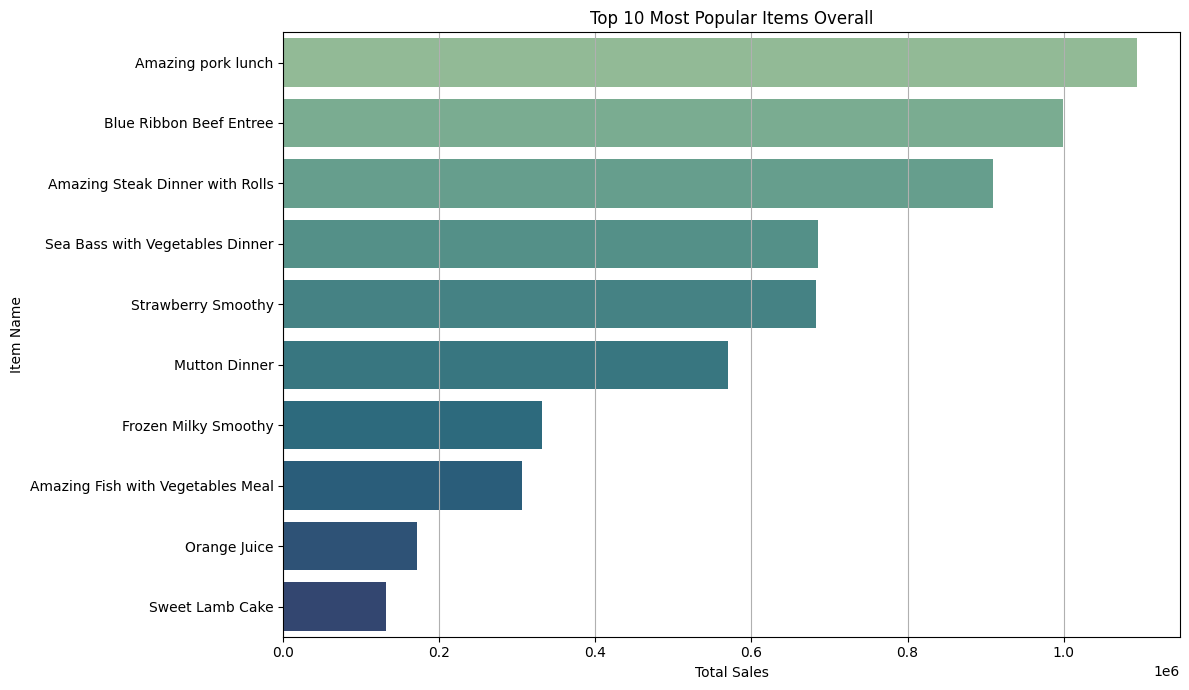


--- Stores Selling the Top 10 Most Popular Items ---
Amazing pork lunch: Bob's Diner
Blue Ribbon Beef Entree: Bob's Diner
Amazing Steak Dinner with Rolls: Bob's Diner
Sea Bass with Vegetables Dinner: Bob's Diner
Strawberry Smoothy: Bob's Diner
Mutton Dinner: Bob's Diner
Frozen Milky Smoothy: Bob's Diner, Corner Cafe
Amazing Fish with Vegetables Meal: Bob's Diner
Orange Juice: Bob's Diner
Sweet Lamb Cake: Bob's Diner

--- Most Popular Item at Each Store ---


,store_name,item_name,total_sales
0,Beachfront Bar,Fantastic Milky Smoothy,3337.77
1,Bob's Diner,Amazing pork lunch,1094500.99
2,Corner Cafe,Awesome Hamburger with Fries,2187.36
3,Fou Cher,Blue Ribbon Fruity Vegi Lunch,16086.04
4,Surfs Up,Steak Meal,3538.35
5,Sweet Shack,Awesome Smoothy,2351.88


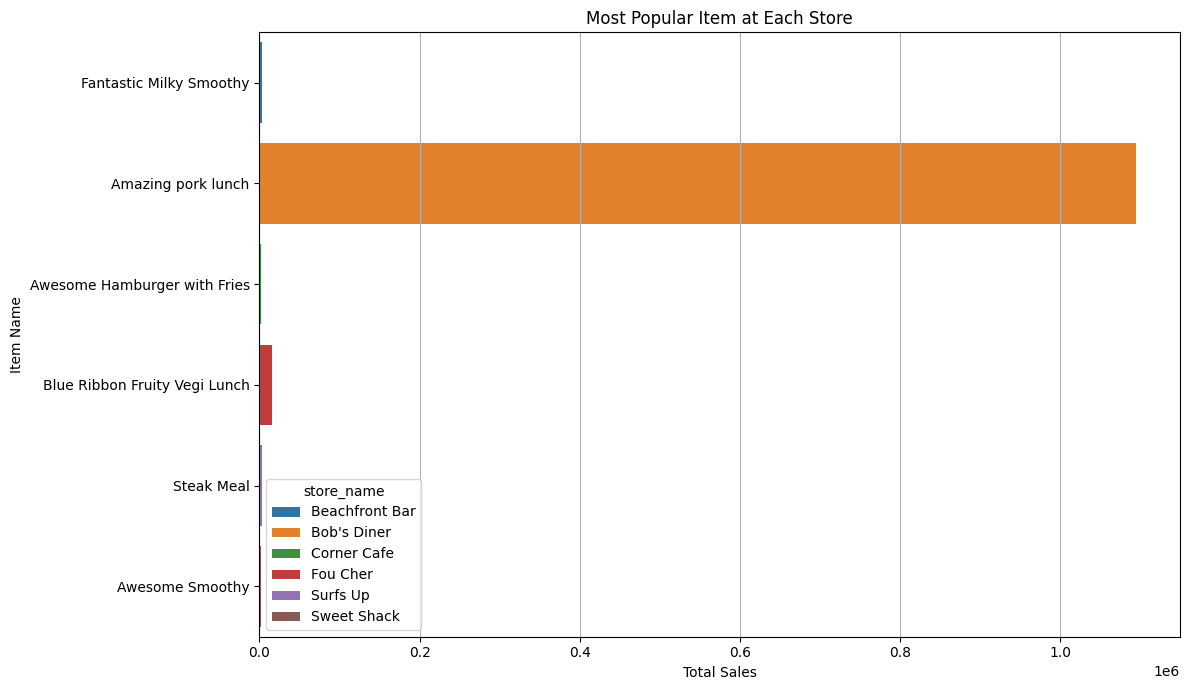

In [44]:
# Ensure 'total_sales' column exists
if 'total_sales' not in final_df.columns:
    final_df['total_sales'] = final_df['price'] * final_df['item_count']

# Identify the most popular items overall (based on total sales)
popular_items_overall = final_df.groupby('item_name')['total_sales'].sum().nlargest(10).reset_index()

print('--- Top 10 Most Popular Items Overall (by Total Sales) ---')
display(popular_items_overall)

plt.figure(figsize=(12, 7))
sns.barplot(data=popular_items_overall, x='total_sales', y='item_name', palette='crest')
plt.title('Top 10 Most Popular Items Overall')
plt.xlabel('Total Sales')
plt.ylabel('Item Name')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

# Identify the stores where these top items are being sold
# For each top item, find all unique store names that sell it
top_items_and_stores = final_df[final_df['item_name'].isin(popular_items_overall['item_name'])][['item_name', 'store_name']].drop_duplicates()

print('\n--- Stores Selling the Top 10 Most Popular Items ---')
for item in popular_items_overall['item_name']:
    stores = top_items_and_stores[top_items_and_stores['item_name'] == item]['store_name'].tolist()
    print(f"{item}: {', '.join(stores)}")

# Find the most popular item at each store
most_popular_item_per_store = final_df.groupby(['store_name', 'item_name'])['total_sales'].sum().reset_index()
idx = most_popular_item_per_store.groupby('store_name')['total_sales'].idxmax()
popular_item_per_store = most_popular_item_per_store.loc[idx].reset_index(drop=True)

print('\n--- Most Popular Item at Each Store ---')
display(popular_item_per_store)

plt.figure(figsize=(12, 7))
sns.barplot(data=popular_item_per_store, x='total_sales', y='item_name', hue='store_name', palette='tab10', dodge=False)
plt.title('Most Popular Item at Each Store')
plt.xlabel('Total Sales')
plt.ylabel('Item Name')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

### Machine Learning: Store Sales Volume vs. Money Per Day

Let's determine if the store with the highest sales volume is also making the most money per day. This requires calculating the average daily sales for each store.

--- Total Sales Per Store ---


,store_name,total_sales
1,Bob's Diner,6337275.69
3,Fou Cher,27885.37
2,Corner Cafe,16551.43
4,Surfs Up,15651.49
0,Beachfront Bar,3796.20
5,Sweet Shack,2578.27



--- Average Money Per Day Per Store ---


,store_name,average_daily_sales
1,Bob's Diner,5782.185849
3,Fou Cher,25.442856
2,Corner Cafe,15.101670
4,Surfs Up,14.280557
0,Beachfront Bar,3.463686
5,Sweet Shack,2.352436



--- Comparison: Total Sales vs. Average Daily Sales Per Store ---


,store_name,total_sales,average_daily_sales
0,Bob's Diner,6337275.69,5782.185849
1,Fou Cher,27885.37,25.442856
2,Corner Cafe,16551.43,15.101670
3,Surfs Up,15651.49,14.280557
4,Beachfront Bar,3796.20,3.463686
5,Sweet Shack,2578.27,2.352436


/tmp/ipykernel_512/1331986059.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=total_sales_per_store, x='total_sales', y='store_name', ax=axes[0], palette='viridis')
/tmp/ipykernel_512/1331986059.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=average_money_per_day_per_store, x='average_daily_sales', y='store_name', ax=axes[1], palette='plasma')


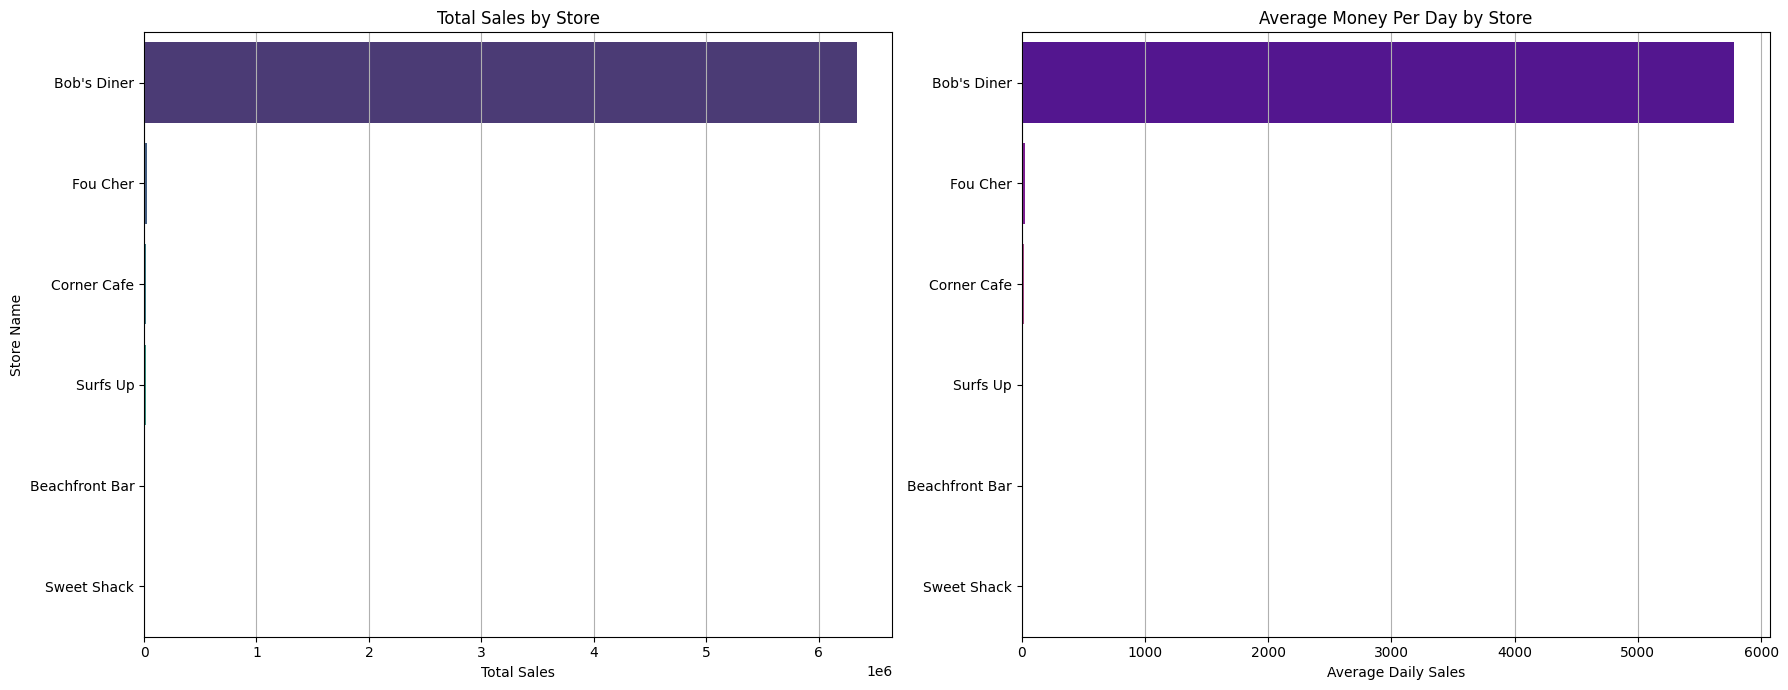

In [46]:
# Ensure 'total_sales' column exists
if 'total_sales' not in final_df.columns:
    final_df['total_sales'] = final_df['price'] * final_df['item_count']

# Calculate total sales per store
total_sales_per_store = final_df.groupby('store_name')['total_sales'].sum().reset_index()
total_sales_per_store = total_sales_per_store.sort_values(by='total_sales', ascending=False)

print('--- Total Sales Per Store ---')
display(total_sales_per_store)

# Calculate average daily sales (money per day) per store
daily_sales_per_store = final_df.groupby(['store_name', 'date'])['total_sales'].sum().reset_index()
average_money_per_day_per_store = daily_sales_per_store.groupby('store_name')['total_sales'].mean().reset_index()
average_money_per_day_per_store = average_money_per_day_per_store.sort_values(by='total_sales', ascending=False)
average_money_per_day_per_store.rename(columns={'total_sales': 'average_daily_sales'}, inplace=True)

print('\n--- Average Money Per Day Per Store ---')
display(average_money_per_day_per_store)

# Merge to compare
comparison_df = total_sales_per_store.merge(average_money_per_day_per_store, on='store_name')

print('\n--- Comparison: Total Sales vs. Average Daily Sales Per Store ---')
display(comparison_df)

# Plotting for visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(data=total_sales_per_store, x='total_sales', y='store_name', ax=axes[0], palette='viridis')
axes[0].set_title('Total Sales by Store')
axes[0].set_xlabel('Total Sales')
axes[0].set_ylabel('Store Name')
axes[0].grid(axis='x')

sns.barplot(data=average_money_per_day_per_store, x='average_daily_sales', y='store_name', ax=axes[1], palette='plasma')
axes[1].set_title('Average Money Per Day by Store')
axes[1].set_xlabel('Average Daily Sales')
axes[1].set_ylabel('') # Keep y-label clear as it's redundant with the first plot
axes[1].grid(axis='x')

plt.tight_layout()
plt.show()

### Exploratory Data Analysis: Restaurant Performance Comparison

Let's compare the performances of the different restaurants to find out which one had the most sales and analyze their sales trends over time.

--- Total Sales by Restaurant ---


,store_name,total_sales
0,Bob's Diner,6337275.69
1,Fou Cher,27885.37
2,Corner Cafe,16551.43
3,Surfs Up,15651.49
4,Beachfront Bar,3796.20
5,Sweet Shack,2578.27



The restaurant with the most sales is: Bob's Diner


/tmp/ipykernel_512/1806748450.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sales_by_restaurant, x='store_name', y='total_sales', palette='viridis')


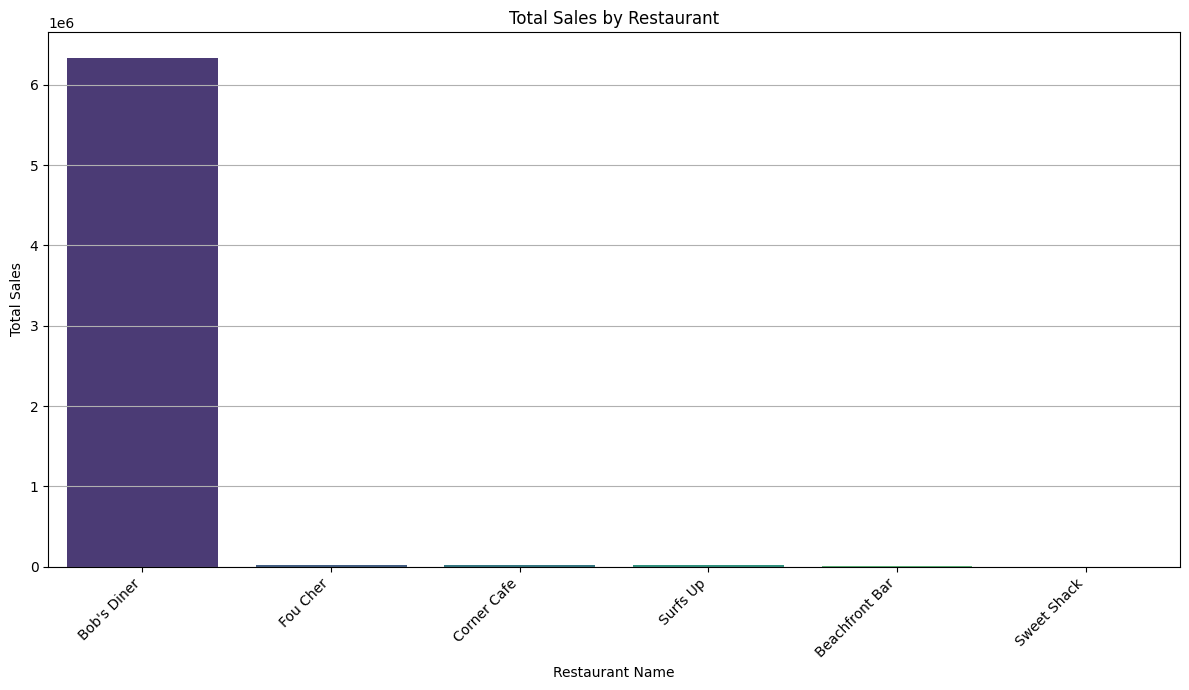

In [48]:
# Ensure 'total_sales' column exists
if 'total_sales' not in final_df.columns:
    final_df['total_sales'] = final_df['price'] * final_df['item_count']

# Calculate total sales by restaurant
sales_by_restaurant = final_df.groupby('store_name')['total_sales'].sum().sort_values(ascending=False).reset_index()

print('--- Total Sales by Restaurant ---')
display(sales_by_restaurant)

# Identify the restaurant with the most sales
most_sales_restaurant = sales_by_restaurant.iloc[0]['store_name']
print(f"\nThe restaurant with the most sales is: {most_sales_restaurant}")

# Plot total sales by restaurant
plt.figure(figsize=(12, 7))
sns.barplot(data=sales_by_restaurant, x='store_name', y='total_sales', palette='viridis')
plt.title('Total Sales by Restaurant')
plt.xlabel('Restaurant Name')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

#### Sales for Each Restaurant Across Different Years, Months, and Days

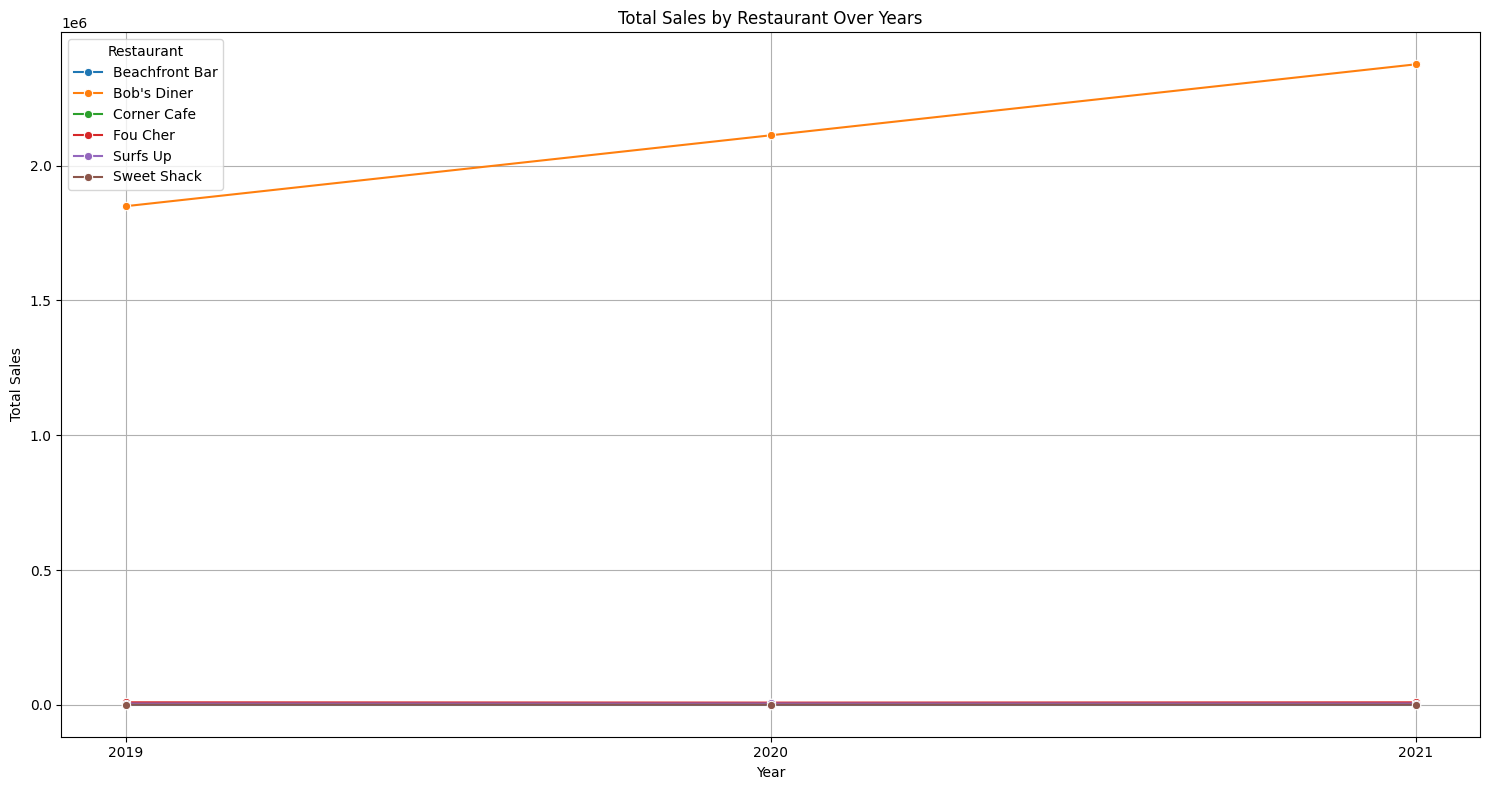

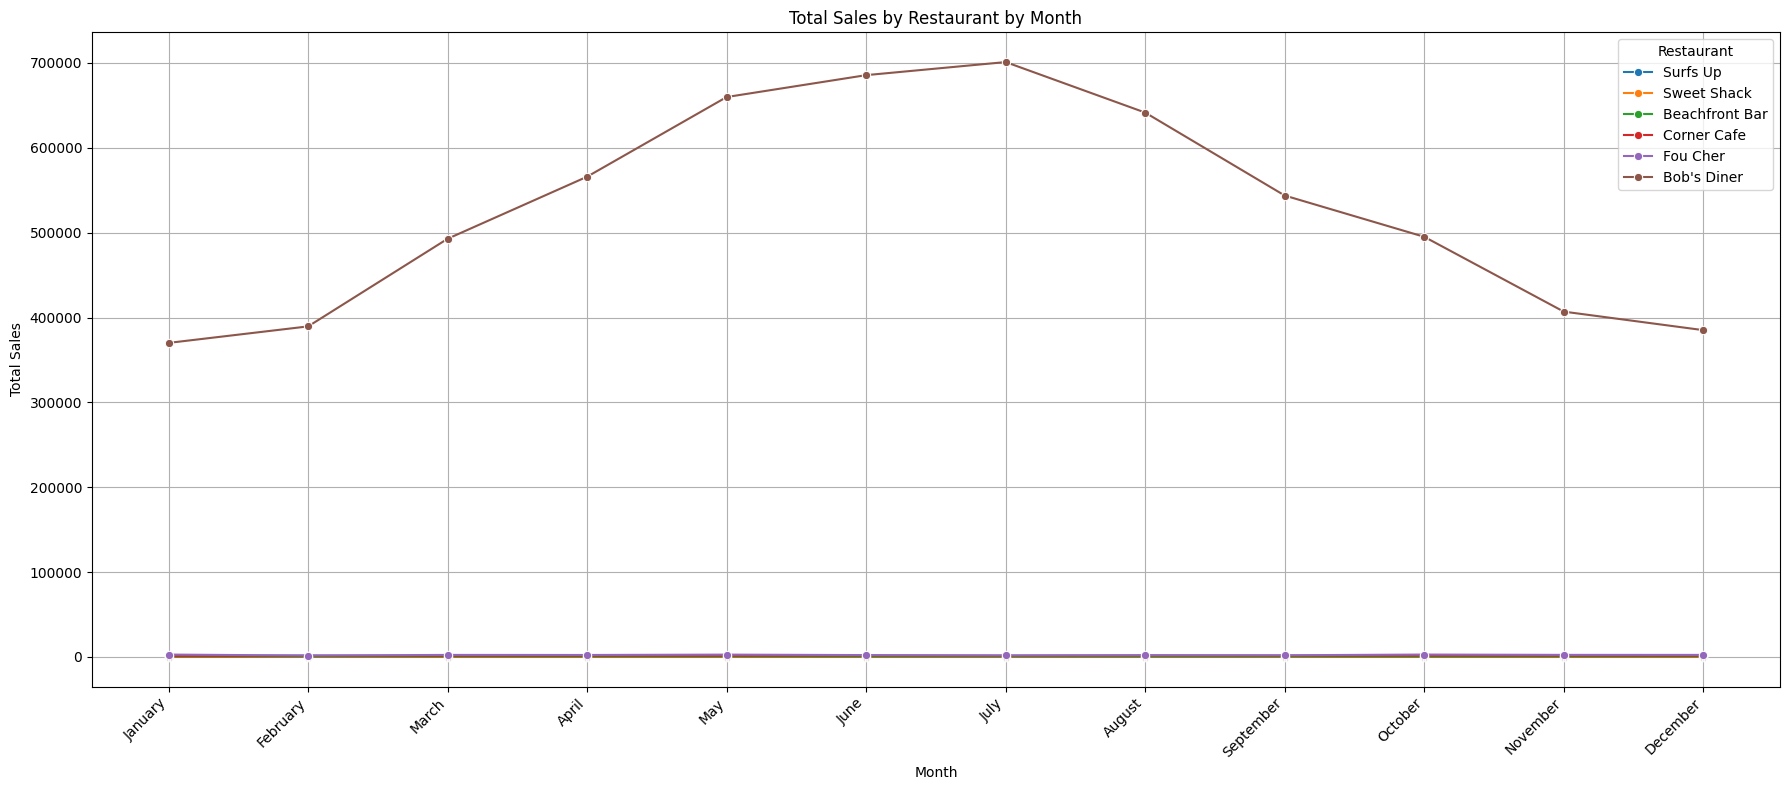

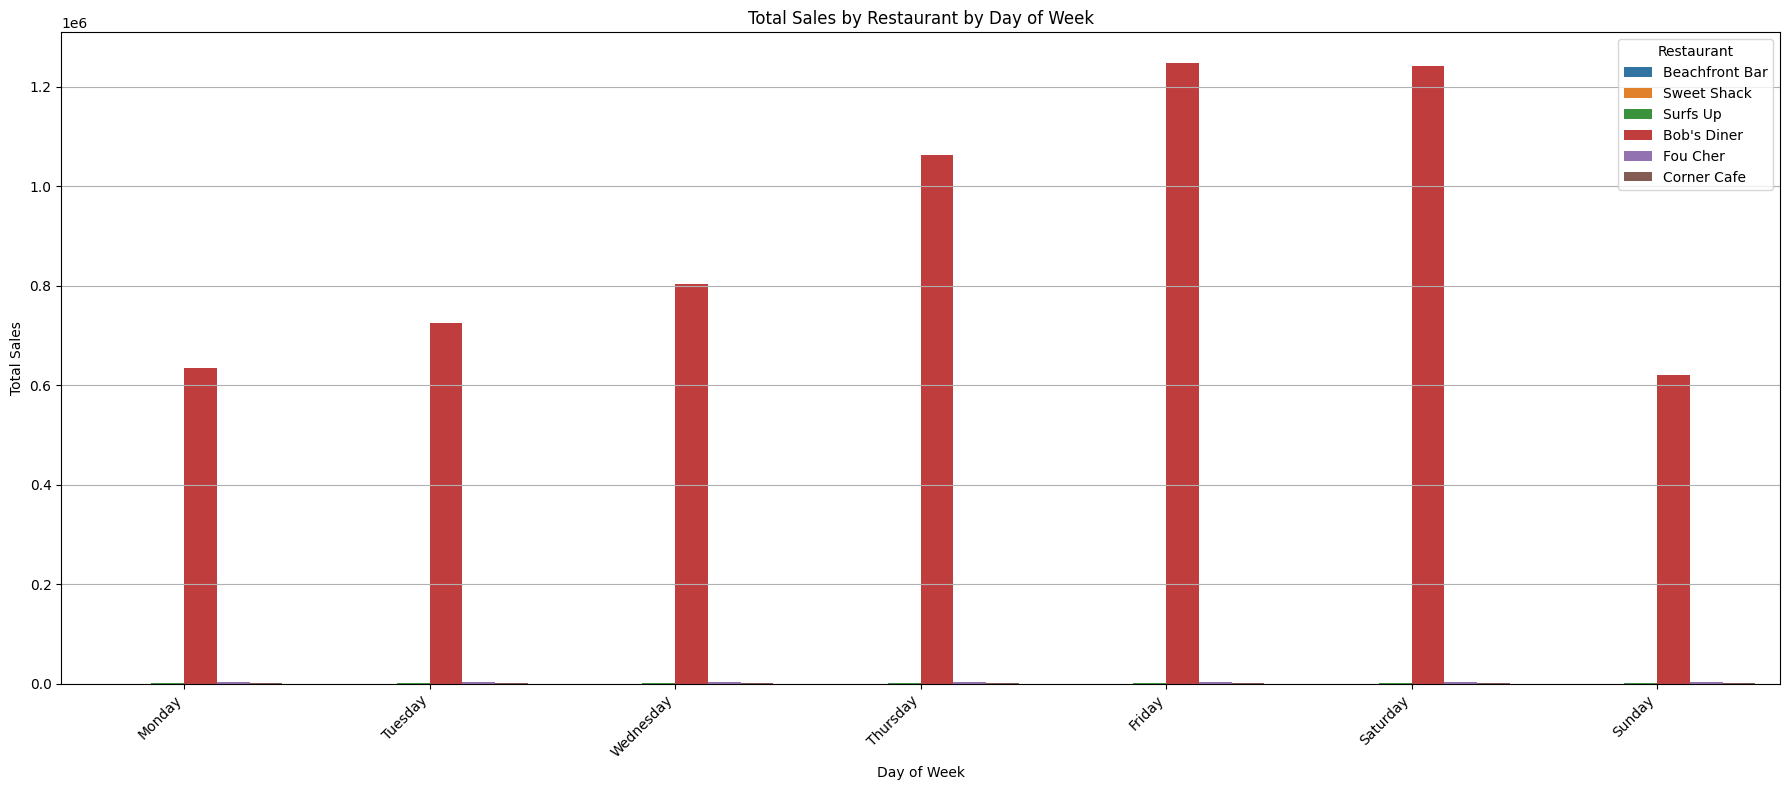

In [49]:
# Extract year, month, and day of week if not already present
if 'year' not in final_df.columns:
    final_df['year'] = final_df['date'].dt.year
if 'month_name' not in final_df.columns:
    final_df['month_name'] = final_df['date'].dt.month_name()
if 'day_of_week' not in final_df.columns:
    final_df['day_of_week'] = final_df['date'].dt.day_name()

# Group by restaurant and year
sales_by_restaurant_year = final_df.groupby(['store_name', 'year'])['total_sales'].sum().reset_index()

plt.figure(figsize=(15, 8))
sns.lineplot(data=sales_by_restaurant_year, x='year', y='total_sales', hue='store_name', marker='o', palette='tab10')
plt.title('Total Sales by Restaurant Over Years')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(final_df['year'].unique())
plt.grid(True)
plt.legend(title='Restaurant')
plt.tight_layout()
plt.show()

# Group by restaurant and month
sales_by_restaurant_month = final_df.groupby(['store_name', 'month_name'])['total_sales'].sum().reset_index()
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
sales_by_restaurant_month['month_name'] = pd.Categorical(sales_by_restaurant_month['month_name'], categories=month_order, ordered=True)
sales_by_restaurant_month = sales_by_restaurant_month.sort_values('month_name')

plt.figure(figsize=(18, 8))
sns.lineplot(data=sales_by_restaurant_month, x='month_name', y='total_sales', hue='store_name', marker='o', palette='tab10')
plt.title('Total Sales by Restaurant by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.legend(title='Restaurant')
plt.tight_layout()
plt.show()

# Group by restaurant and day of week
sales_by_restaurant_day = final_df.groupby(['store_name', 'day_of_week'])['total_sales'].sum().reset_index()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sales_by_restaurant_day['day_of_week'] = pd.Categorical(sales_by_restaurant_day['day_of_week'], categories=day_order, ordered=True)
sales_by_restaurant_day = sales_by_restaurant_day.sort_values('day_of_week')

plt.figure(figsize=(18, 8))
sns.barplot(data=sales_by_restaurant_day, x='day_of_week', y='total_sales', hue='store_name', palette='tab10')
plt.title('Total Sales by Restaurant by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.legend(title='Restaurant')
plt.tight_layout()
plt.show()

### Exploratory Data Analysis: Sales Trends by Month of the Year

Let's examine sales trends across different months of the year to identify any seasonal patterns or other noticeable trends.

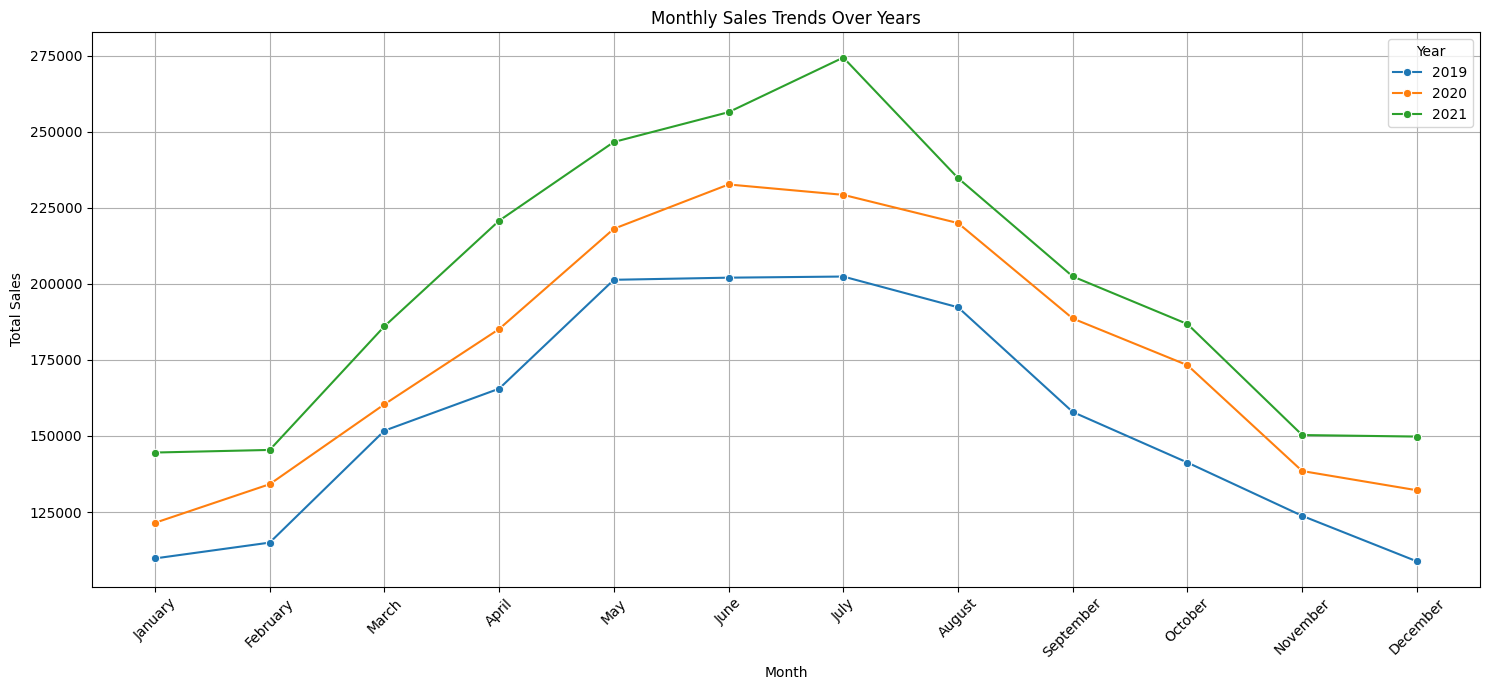

In [51]:
# Ensure 'total_sales' column exists
if 'total_sales' not in final_df.columns:
    final_df['total_sales'] = final_df['price'] * final_df['item_count']

# Extract month and year
final_df['month'] = final_df['date'].dt.month_name()
final_df['year'] = final_df['date'].dt.year

# Calculate total sales per month, averaged over the years
sales_by_month_year = final_df.groupby(['year', 'month'])['total_sales'].sum().reset_index()

# To get average trend, let's pivot and then plot
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

sales_by_month_year['month'] = pd.Categorical(sales_by_month_year['month'], categories=month_order, ordered=True)
sales_by_month_year = sales_by_month_year.sort_values(['year', 'month'])

# Plot sales trend for each year
plt.figure(figsize=(15, 7))
sns.lineplot(data=sales_by_month_year, x='month', y='total_sales', hue='year', marker='o', palette='tab10')
plt.title('Monthly Sales Trends Over Years')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend(title='Year')
plt.tight_layout()
plt.show()

### Exploratory Data Analysis: Sales Fluctuation Across Days of the Week

Now, let's analyze how sales fluctuate across different days of the week. We will extract the day of the week from the 'date' column and visualize the average daily sales.

--- Sales by Day of Week ---


,day_of_week,total_sales
0,Monday,644799.97
1,Tuesday,734598.46
2,Wednesday,812613.31
3,Thursday,1073534.52
4,Friday,1257338.16
5,Saturday,1250574.32
6,Sunday,630279.71


/tmp/ipykernel_512/3476745468.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sales_by_day, x='day_of_week', y='total_sales', palette='viridis')


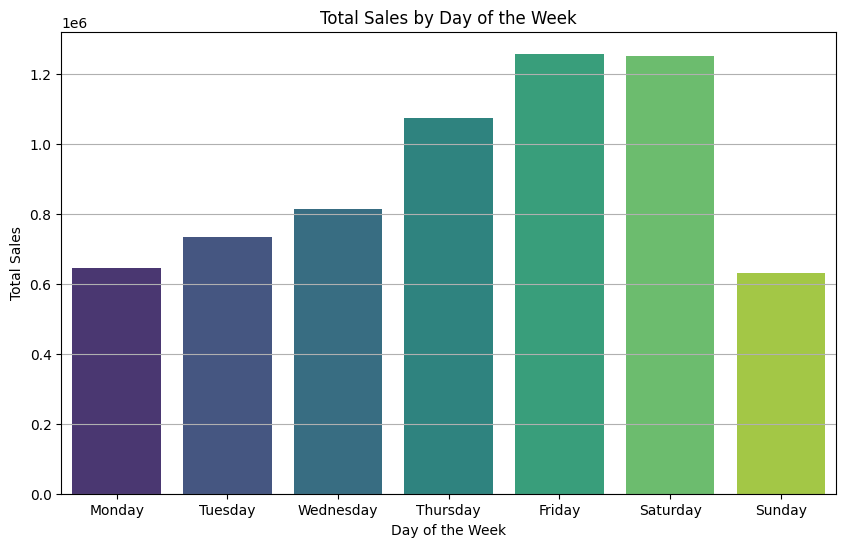

In [53]:
# Ensure 'total_sales' column exists (it should have been created in the previous step)
if 'total_sales' not in final_df.columns:
    final_df['total_sales'] = final_df['price'] * final_df['item_count']

# Extract day of the week
final_df['day_of_week'] = final_df['date'].dt.day_name()

# Calculate average daily sales per day of the week
sales_by_day = final_df.groupby('day_of_week')['total_sales'].sum().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']).reset_index()

print('--- Sales by Day of Week ---')
display(sales_by_day)

# Plot sales by day of the week
plt.figure(figsize=(10, 6))
sns.barplot(data=sales_by_day, x='day_of_week', y='total_sales', palette='viridis')
plt.title('Total Sales by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Total Sales')
plt.grid(axis='y')
plt.show()

### Machine Learning: Most Expensive Item and Calorie Count at Each Restaurant

Let's identify the most expensive item at each restaurant and determine its calorie count.

--- Most Expensive Item at Each Restaurant with its Calorie Count ---


,store_name,item_name,max_price,kcal
0,Beachfront Bar,Sweet Vegi Soft Drink,5.70,538
1,Bob's Diner,Sweet Fruity Cake,29.22,931
2,Corner Cafe,Pike Lunch,26.37,653
3,Fou Cher,Blue Ribbon Fruity Vegi Lunch,53.98,881
4,Surfs Up,Steak Meal,26.21,607
5,Sweet Shack,Blue Ribbon Frozen Milky Cake,7.70,636


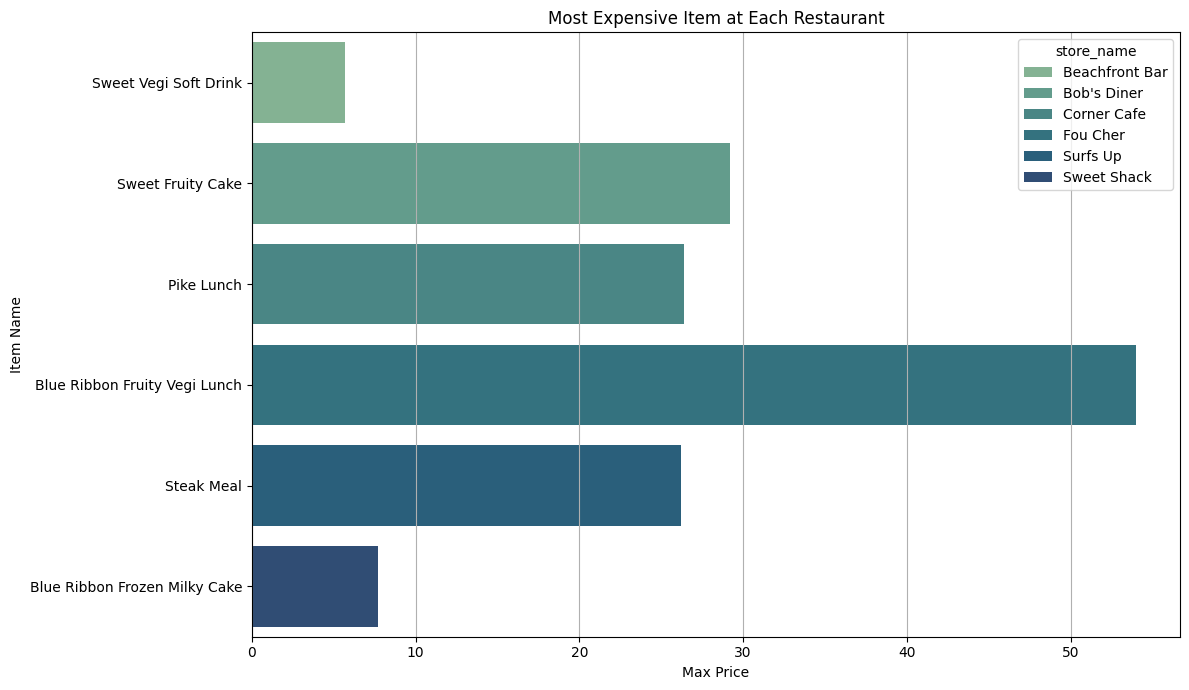

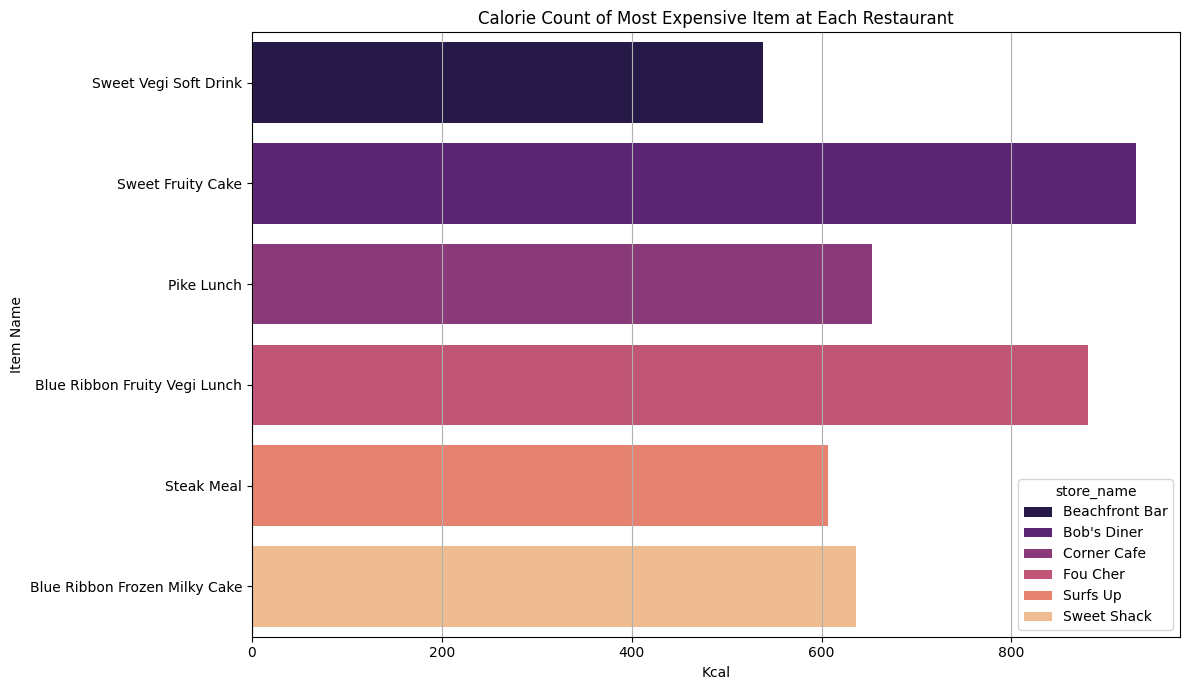

In [54]:
# Group by store and item to find the maximum price for each item in each store
max_price_per_item_per_store = final_df.groupby(['store_name', 'item_name']).agg(
    max_price=('price', 'max'),
    kcal=('kcal', 'first') # Assuming kcal is constant for an item, take the first
).reset_index()

# Find the most expensive item per store
idx = max_price_per_item_per_store.groupby('store_name')['max_price'].idxmax()
most_expensive_item_per_store = max_price_per_item_per_store.loc[idx].reset_index(drop=True)

print('--- Most Expensive Item at Each Restaurant with its Calorie Count ---')
display(most_expensive_item_per_store)

# Plotting for visualization
plt.figure(figsize=(12, 7))
sns.barplot(data=most_expensive_item_per_store, x='max_price', y='item_name', hue='store_name', palette='crest', dodge=False)
plt.title('Most Expensive Item at Each Restaurant')
plt.xlabel('Max Price')
plt.ylabel('Item Name')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 7))
sns.barplot(data=most_expensive_item_per_store, x='kcal', y='item_name', hue='store_name', palette='magma', dodge=False)
plt.title('Calorie Count of Most Expensive Item at Each Restaurant')
plt.xlabel('Kcal')
plt.ylabel('Item Name')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

### Forecasting using Machine Learning Algorithms: Feature Engineering

To prepare for forecasting, we need to generate necessary features for the development of these models, like day of the week, quarter of the year, month, year, day of the month. We'll extract these from the 'date' column and create a daily aggregated sales dataframe.

In [77]:
# Ensure 'total_sales' column exists
if 'total_sales' not in final_df.columns:
    final_df['total_sales'] = final_df['price'] * final_df['item_count']

# Create time-based features on a copy to avoid SettingWithCopyWarning
df_features = final_df.copy()
df_features['year'] = df_features['date'].dt.year
df_features['month'] = df_features['date'].dt.month
df_features['day_of_month'] = df_features['date'].dt.day
df_features['day_of_week'] = df_features['date'].dt.dayofweek # Monday=0, Sunday=6
df_features['quarter'] = df_features['date'].dt.quarter

# Aggregate daily sales for modeling, ensuring all features are present
daily_sales_df = df_features.groupby('date')['total_sales'].sum().reset_index()

# Re-add the time features to the daily sales dataframe from its own date column
daily_sales_df['year'] = daily_sales_df['date'].dt.year
daily_sales_df['month'] = daily_sales_df['date'].dt.month
daily_sales_df['day_of_month'] = daily_sales_df['date'].dt.day
daily_sales_df['day_of_week'] = daily_sales_df['date'].dt.dayofweek
daily_sales_df['quarter'] = daily_sales_df['date'].dt.quarter

print('--- Daily Sales DataFrame with Features Head ---')
display(daily_sales_df.head())
print('\n--- Daily Sales DataFrame with Features Info ---')
daily_sales_df.info()

--- Daily Sales DataFrame with Features Head ---


,date,total_sales,year,month,day_of_month,day_of_week,quarter
0,2019-01-01,4023.00,2019,1,1,1,1
1,2019-01-02,3074.69,2019,1,2,2,1
2,2019-01-03,4062.71,2019,1,3,3,1
3,2019-01-04,5006.81,2019,1,4,4,1
4,2019-01-05,4927.53,2019,1,5,5,1



--- Daily Sales DataFrame with Features Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1096 non-null   datetime64[ns]
 1   total_sales   1096 non-null   float64       
 2   year          1096 non-null   int32         
 3   month         1096 non-null   int32         
 4   day_of_month  1096 non-null   int32         
 5   day_of_week   1096 non-null   int32         
 6   quarter       1096 non-null   int32         
dtypes: datetime64[ns](1), float64(1), int32(5)
memory usage: 38.7 KB


### Forecasting using Machine Learning Algorithms: Data Splitting

Next, we will split the data into training and testing sets. As instructed, we will use the data from the last six months as the testing data.

In [78]:
# Sort the data by date to ensure proper time-series splitting
daily_sales_df = daily_sales_df.sort_values('date').reset_index(drop=True)

# Determine the split point (last 6 months)
split_date = daily_sales_df['date'].max() - pd.DateOffset(months=6)

# Split data into training and testing sets
train_df = daily_sales_df[daily_sales_df['date'] <= split_date]
test_df = daily_sales_df[daily_sales_df['date'] > split_date]

# Define features (X) and target (y)
features = ['year', 'month', 'day_of_month', 'day_of_week', 'quarter']
X_train = train_df[features]
y_train = train_df['total_sales']
X_test = test_df[features]
y_test = test_df['total_sales']

print(f"Training data shape: {train_df.shape}")
print(f"Testing data shape: {test_df.shape}")
print(f"Split date: {split_date.strftime('%Y-%m-%d')}")

Training data shape: (912, 7)
Testing data shape: (184, 7)
Split date: 2021-06-30


### Forecasting using Machine Learning Algorithms: Model Building and Comparison

Now, we will build and compare Linear Regression, Random Forest, and XGBoost models for sales predictions. We will compute the Root Mean Squared Error (RMSE) values for each model to compare their performances.


--- Training Linear Regression Model ---
Linear Regression RMSE: 2391.70

--- Training Random Forest Model ---
Random Forest RMSE: 838.89

--- Training XGBoost Model ---
XGBoost RMSE: 738.76

--- Model Comparison (RMSE) ---
Linear Regression: 2391.70
Random Forest: 838.89
XGBoost: 738.76

The best performing model is: XGBoost with RMSE: 738.76


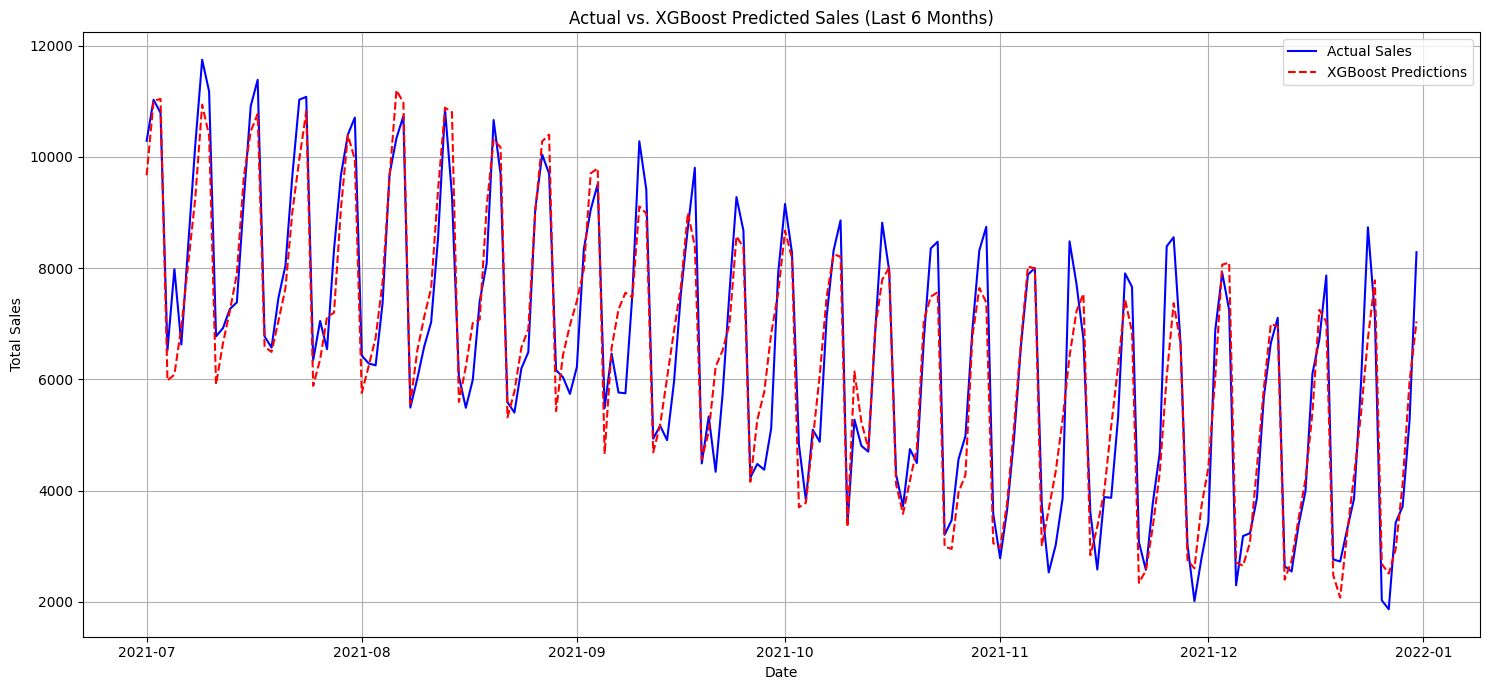

In [79]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_squared_error
import math

# Initialize models
lr_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1) # Use all available cores
xgb_model = xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1)

models = {
    'Linear Regression': lr_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

rmse_results = {}
predictions = {}

for name, model in models.items():
    print(f"\n--- Training {name} Model ---")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = math.sqrt(mean_squared_error(y_test, y_pred))
    rmse_results[name] = rmse
    predictions[name] = y_pred
    print(f"{name} RMSE: {rmse:.2f}")

print('\n--- Model Comparison (RMSE) ---')
for name, rmse in rmse_results.items():
    print(f"{name}: {rmse:.2f}")

# Visualize predictions vs actuals for the best model (e.g., the one with lowest RMSE)
best_model_name = min(rmse_results, key=rmse_results.get)
print(f"\nThe best performing model is: {best_model_name} with RMSE: {rmse_results[best_model_name]:.2f}")

plt.figure(figsize=(15, 7))
plt.plot(test_df['date'], y_test, label='Actual Sales', color='blue')
plt.plot(test_df['date'], predictions[best_model_name], label=f'{best_model_name} Predictions', color='red', linestyle='--')
plt.title(f'Actual vs. {best_model_name} Predicted Sales (Last 6 Months)')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Forecasting using Machine Learning Algorithms: Next Year's Forecast

Finally, we will use the best-performing model to make a forecast for the next year.

Using the best performing model for forecasting: XGBoost

--- Forecasted Sales for Next Year Head ---


,date,year,month,day_of_month,day_of_week,quarter,forecasted_sales
0,2022-01-01,2022,1,1,5,1,7123.499023
1,2022-01-02,2022,1,2,6,1,2755.063721
2,2022-01-03,2022,1,3,0,1,2481.572021
3,2022-01-04,2022,1,4,1,1,3230.484131
4,2022-01-05,2022,1,5,2,1,3553.956787


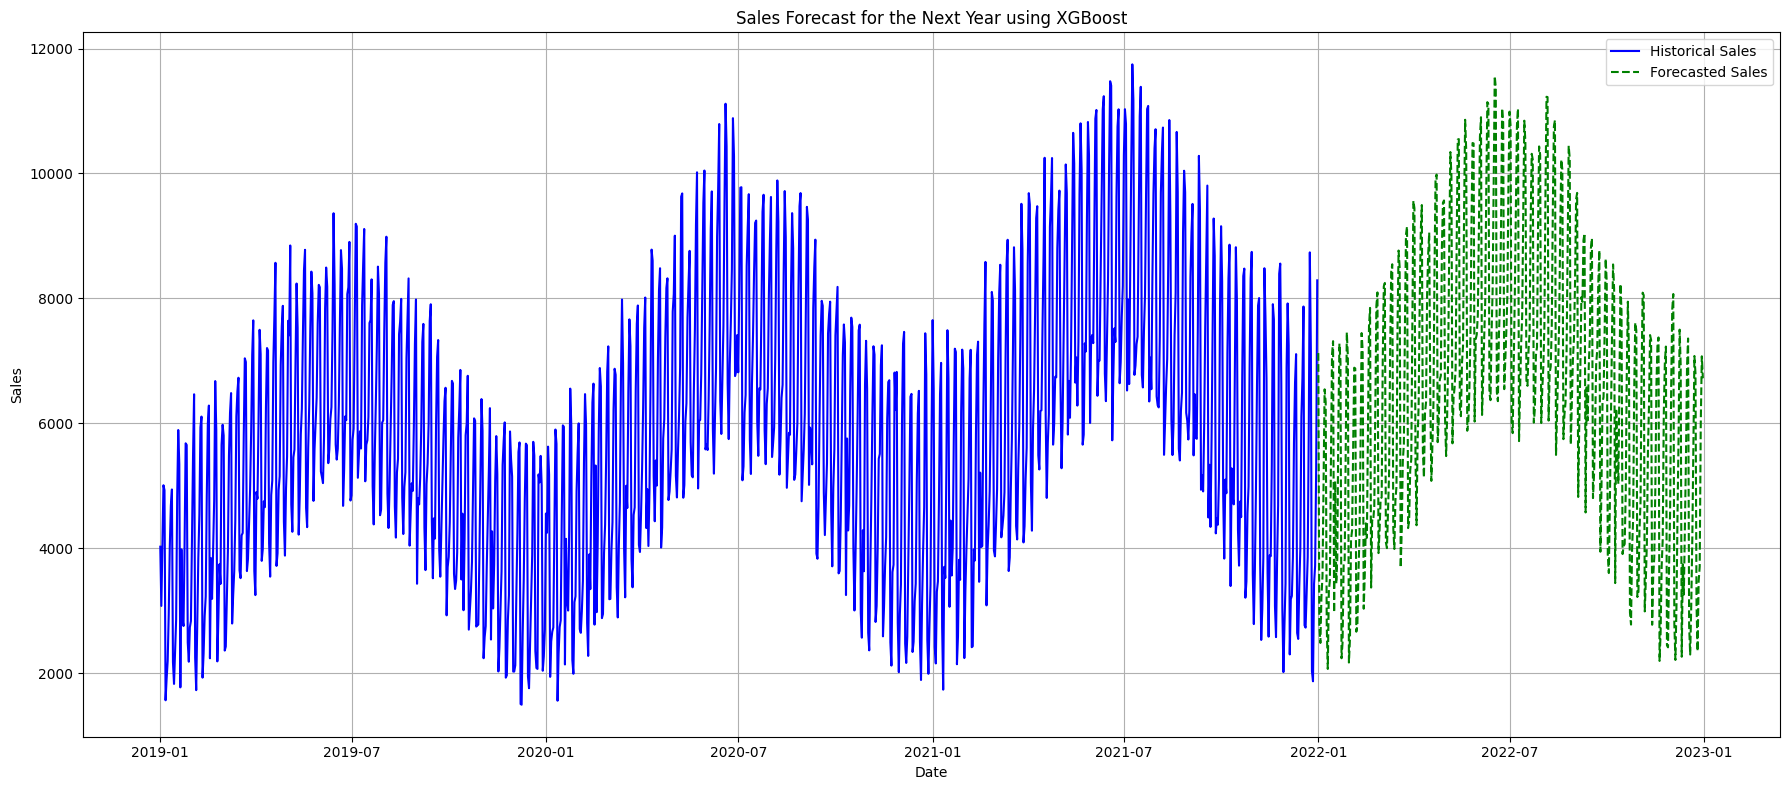

In [81]:
# Identify the best performing model from the comparison
best_model_name = min(rmse_results, key=rmse_results.get)
best_model = models[best_model_name]
print(f"Using the best performing model for forecasting: {best_model_name}")

# Generate future dates for the next year (starting from the day after the last date in the dataset)
last_historical_date = daily_sales_df['date'].max()
future_dates = pd.date_range(start=last_historical_date + pd.DateOffset(days=1), periods=365, freq='D')

# Create a DataFrame for future predictions with the necessary features
future_df = pd.DataFrame({'date': future_dates})
future_df['year'] = future_df['date'].dt.year
future_df['month'] = future_df['date'].dt.month
future_df['day_of_month'] = future_df['date'].dt.day
future_df['day_of_week'] = future_df['date'].dt.dayofweek
future_df['quarter'] = future_df['date'].dt.quarter

# Make predictions for the next year
X_future = future_df[features]
future_predictions = best_model.predict(X_future)
future_df['forecasted_sales'] = future_predictions

# Ensure predictions are not negative (sales cannot be negative)
future_df['forecasted_sales'] = future_df['forecasted_sales'].apply(lambda x: max(0, x))

print('\n--- Forecasted Sales for Next Year Head ---')
display(future_df.head())

# Combine historical data and forecast for visualization
# Using train_df and test_df to get the full historical context for plotting
historical_data_for_plot = pd.concat([train_df[['date', 'total_sales']], test_df[['date', 'total_sales']]])

plt.figure(figsize=(18, 8))
sns.lineplot(data=historical_data_for_plot, x='date', y='total_sales', label='Historical Sales', color='blue')
sns.lineplot(data=future_df, x='date', y='forecasted_sales', label='Forecasted Sales', color='green', linestyle='--')
plt.title(f'Sales Forecast for the Next Year using {best_model_name}')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Machine Learning: Feature Engineering for Forecasting

To prepare for forecasting, we need to create additional time-based features from the 'date' column such as year, month, day of month, day of week, and quarter.

In [71]:
# Ensure 'total_sales' column exists
if 'total_sales' not in final_df.columns:
    final_df['total_sales'] = final_df['price'] * final_df['item_count']

# Create time-based features
df_features = final_df.copy()
df_features['year'] = df_features['date'].dt.year
df_features['month'] = df_features['date'].dt.month
df_features['day_of_month'] = df_features['date'].dt.day
df_features['day_of_week'] = df_features['date'].dt.dayofweek # Monday=0, Sunday=6
df_features['quarter'] = df_features['date'].dt.quarter

# Aggregate daily sales for modeling
daily_sales_df = df_features.groupby('date')['total_sales'].sum().reset_index()

# Re-add the time features to the daily sales dataframe
daily_sales_df['year'] = daily_sales_df['date'].dt.year
daily_sales_df['month'] = daily_sales_df['date'].dt.month
daily_sales_df['day_of_month'] = daily_sales_df['date'].dt.day
daily_sales_df['day_of_week'] = daily_sales_df['date'].dt.dayofweek
daily_sales_df['quarter'] = daily_sales_df['date'].dt.quarter

print('--- Daily Sales DataFrame with Features Head ---')
display(daily_sales_df.head())
print('\n--- Daily Sales DataFrame with Features Info ---')
daily_sales_df.info()

--- Daily Sales DataFrame with Features Head ---


,date,total_sales,year,month,day_of_month,day_of_week,quarter
0,2019-01-01,4023.00,2019,1,1,1,1
1,2019-01-02,3074.69,2019,1,2,2,1
2,2019-01-03,4062.71,2019,1,3,3,1
3,2019-01-04,5006.81,2019,1,4,4,1
4,2019-01-05,4927.53,2019,1,5,5,1



--- Daily Sales DataFrame with Features Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1096 non-null   datetime64[ns]
 1   total_sales   1096 non-null   float64       
 2   year          1096 non-null   int32         
 3   month         1096 non-null   int32         
 4   day_of_month  1096 non-null   int32         
 5   day_of_week   1096 non-null   int32         
 6   quarter       1096 non-null   int32         
dtypes: datetime64[ns](1), float64(1), int32(5)
memory usage: 38.7 KB


### Machine Learning: Data Splitting for Forecasting

We will use the last six months of data for testing, and the remaining data for training the models.

In [72]:
# Sort the data by date to ensure proper splitting
daily_sales_df = daily_sales_df.sort_values('date')

# Determine the split point (last 6 months)
split_date = daily_sales_df['date'].max() - pd.DateOffset(months=6)

# Split data into training and testing sets
train_df = daily_sales_df[daily_sales_df['date'] <= split_date]
test_df = daily_sales_df[daily_sales_df['date'] > split_date]

X_train = train_df[['year', 'month', 'day_of_month', 'day_of_week', 'quarter']]
y_train = train_df['total_sales']
X_test = test_df[['year', 'month', 'day_of_month', 'day_of_week', 'quarter']]
y_test = test_df['total_sales']

print(f"Training data shape: {train_df.shape}")
print(f"Testing data shape: {test_df.shape}")
print(f"Split date: {split_date}")

Training data shape: (912, 7)
Testing data shape: (184, 7)
Split date: 2021-06-30 00:00:00


### Machine Learning: Model Building and Comparison

Now, let's build and compare Linear Regression, Random Forest, and XGBoost models for sales prediction. We will evaluate their performance using Root Mean Squared Error (RMSE).


--- Training Linear Regression Model ---
Linear Regression RMSE: 2391.70

--- Training Random Forest Model ---
Random Forest RMSE: 838.89

--- Training XGBoost Model ---
XGBoost RMSE: 738.76

--- Model Comparison (RMSE) ---
Linear Regression: 2391.70
Random Forest: 838.89
XGBoost: 738.76

The best performing model is: XGBoost with RMSE: 738.76


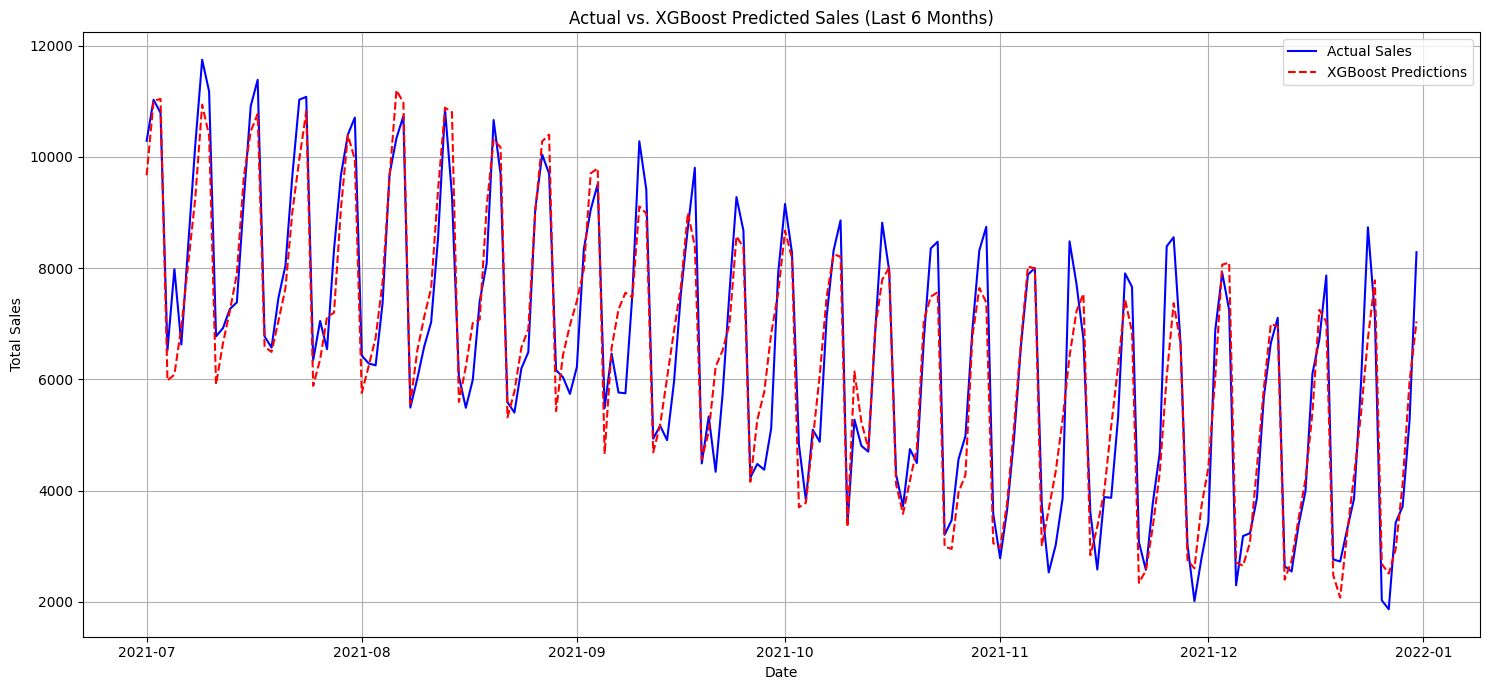

In [73]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_squared_error
import math

# Initialize models
lr_model = LinearRegression()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
xgb_model = xgb.XGBRegressor(n_estimators=100, random_state=42)

models = {
    'Linear Regression': lr_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

rmse_results = {}
predictions = {}

for name, model in models.items():
    print(f"\n--- Training {name} Model ---")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = math.sqrt(mean_squared_error(y_test, y_pred))
    rmse_results[name] = rmse
    predictions[name] = y_pred
    print(f"{name} RMSE: {rmse:.2f}")

print('\n--- Model Comparison (RMSE) ---')
for name, rmse in rmse_results.items():
    print(f"{name}: {rmse:.2f}")

# Visualize predictions vs actuals for the best model (e.g., XGBoost)
best_model_name = min(rmse_results, key=rmse_results.get)
print(f"\nThe best performing model is: {best_model_name} with RMSE: {rmse_results[best_model_name]:.2f}")

plt.figure(figsize=(15, 7))
plt.plot(test_df['date'], y_test, label='Actual Sales', color='blue')
plt.plot(test_df['date'], predictions[best_model_name], label=f'{best_model_name} Predictions', color='red', linestyle='--')
plt.title(f'Actual vs. {best_model_name} Predicted Sales (Last 6 Months)')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Machine Learning: Forecasting for the Next Year

Based on the model comparison, we will use the best performing model to forecast sales for the next year.

Using the best performing model for forecasting: XGBoost

--- Forecasted Sales for Next Year Head ---


,date,year,month,day_of_month,day_of_week,quarter,forecasted_sales
0,2022-01-01,2022,1,1,5,1,7123.499023
1,2022-01-02,2022,1,2,6,1,2755.063721
2,2022-01-03,2022,1,3,0,1,2481.572021
3,2022-01-04,2022,1,4,1,1,3230.484131
4,2022-01-05,2022,1,5,2,1,3553.956787


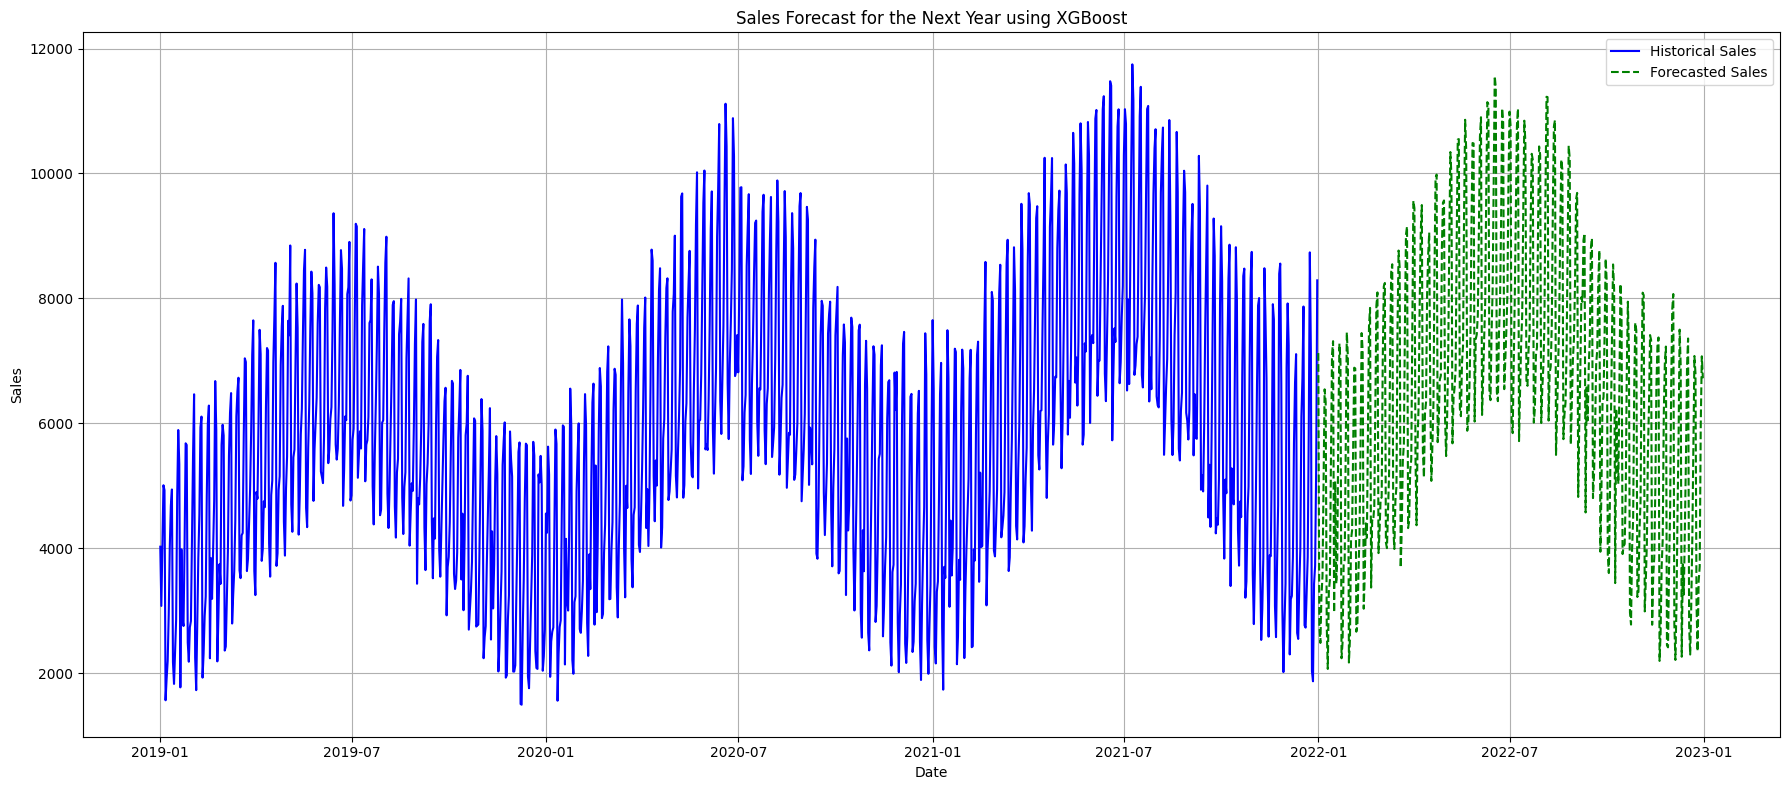

In [75]:
# Identify the best performing model
best_model_name = min(rmse_results, key=rmse_results.get)
best_model = models[best_model_name]
print(f"Using the best performing model for forecasting: {best_model_name}")

# Generate future dates for the next year (starting from the day after the last test date)
last_date = daily_sales_df['date'].max()
future_dates = pd.date_range(start=last_date + pd.DateOffset(days=1), periods=365, freq='D')

# Create a DataFrame for future predictions
future_df = pd.DataFrame({'date': future_dates})
future_df['year'] = future_df['date'].dt.year
future_df['month'] = future_df['date'].dt.month
future_df['day_of_month'] = future_df['date'].dt.day
future_df['day_of_week'] = future_df['date'].dt.dayofweek
future_df['quarter'] = future_df['date'].dt.quarter

# Make predictions for the next year
X_future = future_df[['year', 'month', 'day_of_month', 'day_of_week', 'quarter']]
future_predictions = best_model.predict(X_future)
future_df['forecasted_sales'] = future_predictions

print('\n--- Forecasted Sales for Next Year Head ---')
display(future_df.head())

# Combine historical data and forecast for visualization
combined_df = pd.concat([daily_sales_df[['date', 'total_sales']], future_df[['date', 'forecasted_sales']]], ignore_index=True)

plt.figure(figsize=(18, 8))
sns.lineplot(data=combined_df, x='date', y='total_sales', label='Historical Sales', color='blue')
sns.lineplot(data=combined_df, x='date', y='forecasted_sales', label='Forecasted Sales', color='green', linestyle='--')
plt.title(f'Sales Forecast for the Next Year using {best_model_name}')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Exploratory Data Analysis: Overall Sales Pattern

Let's examine the overall sales to understand the pattern. This involves calculating daily total sales and visualizing them over time.

--- Daily Sales Head ---


,date,total_sales
0,2019-01-01,4023.00
1,2019-01-02,3074.69
2,2019-01-03,4062.71
3,2019-01-04,5006.81
4,2019-01-05,4927.53



--- Daily Sales Descriptive Statistics ---


,date,total_sales
count,1096,1096.000000
mean,2020-07-01 12:00:00,5842.827053
min,2019-01-01 00:00:00,1492.680000
25%,2019-10-01 18:00:00,4135.432500
50%,2020-07-01 12:00:00,5745.950000
75%,2021-04-01 06:00:00,7406.320000
max,2021-12-31 00:00:00,11746.770000
std,NaN,2208.204434


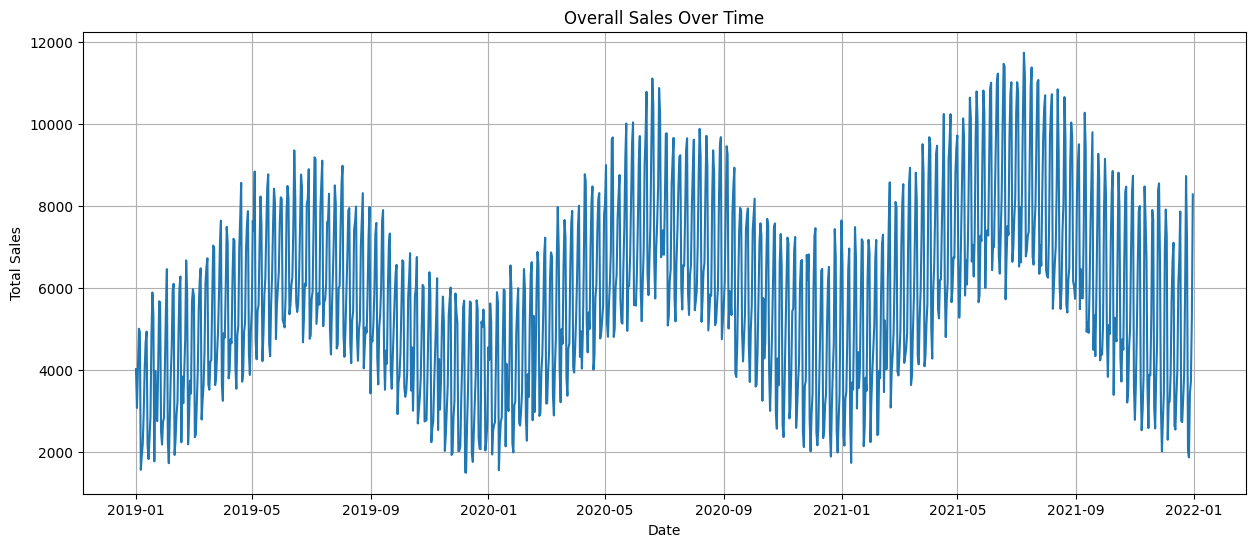

In [69]:
# Calculate daily total sales
final_df['total_sales'] = final_df['price'] * final_df['item_count']
daily_sales = final_df.groupby('date')['total_sales'].sum().reset_index()

print('--- Daily Sales Head ---')
display(daily_sales.head())
print('\n--- Daily Sales Descriptive Statistics ---')
display(daily_sales.describe())

# Plot overall sales over time
plt.figure(figsize=(15, 6))
sns.lineplot(data=daily_sales, x='date', y='total_sales')
plt.title('Overall Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid(True)
plt.show()